In [4]:
from req_functions_from_ApproxSP import *
import pandas as pd
from AccompliceManipulation import *
import pandas as pd
import ast
from tqdm import tqdm

**Mallows**

In [41]:
df = pd.read_csv("mallows_gain_test.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_gain_test.csv', index=False)


500it [00:01, 295.68it/s]


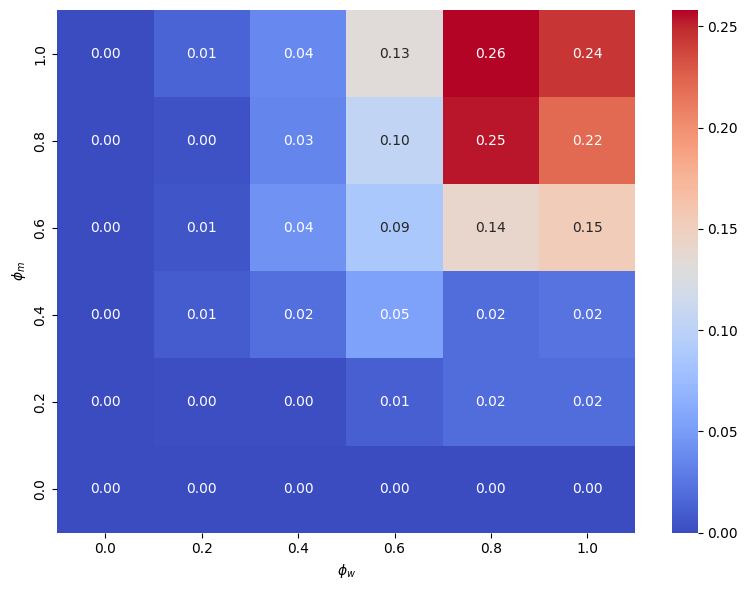

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_df[value_col] = heatmap_df[value_col] / 10  # Scale here
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    #plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, scale=1):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_df[value_col] = heatmap_df[value_col] / scale  # Scale here
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    
    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
#plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "mallows_max_best_benefit_acc")
#plot_heatmap_sum(df, "acc_freq_instance", "Average Frequency of Accomplice Manipulation (Instances)", "mallows_acc_freq_instance")
#plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "mallows_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "mallows_number_acc_pairs_10")


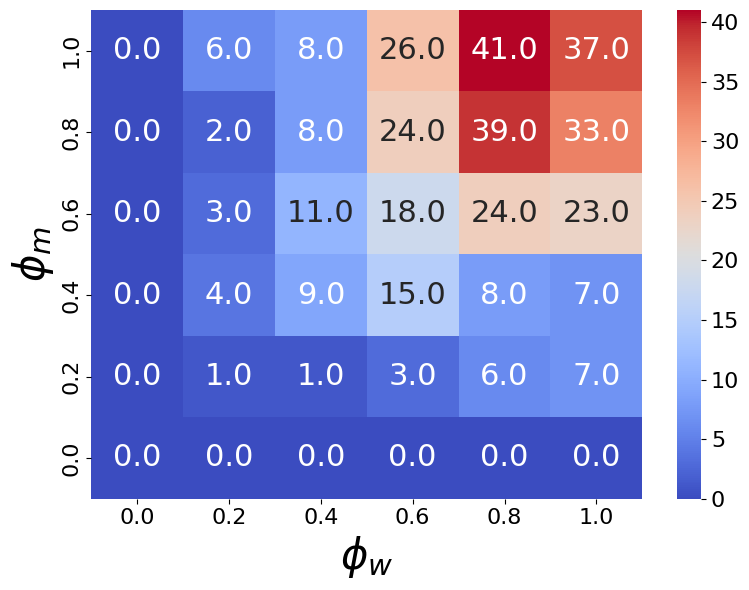

In [1]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["acc_freq_instance"].sum().reset_index()


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="acc_freq_instance")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_acc_freq_instance.pdf", format="pdf")
plt.show()


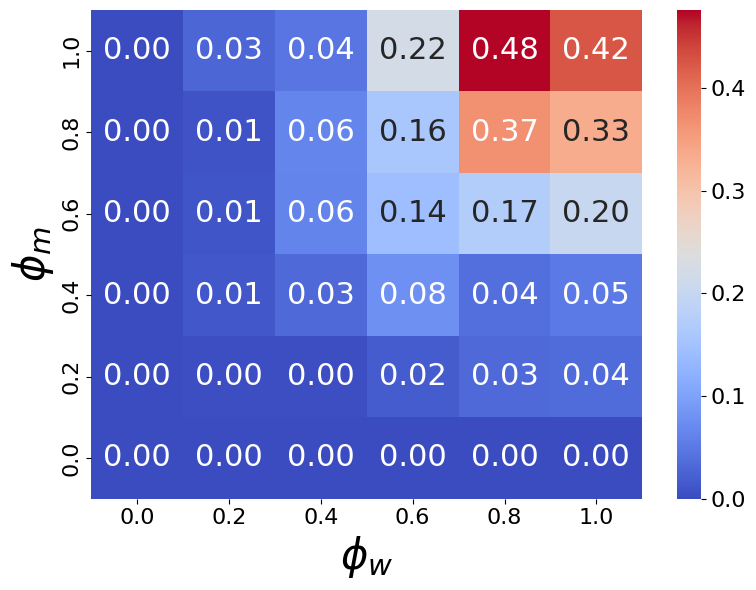

In [13]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["avg_best_benefit_acc"].mean().reset_index()

#heatmap_data["avg_best_benefit_acc"] = heatmap_data["avg_best_benefit_acc"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="avg_best_benefit_acc")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_avg_best_benefit_acc.pdf", format="pdf")
plt.show()

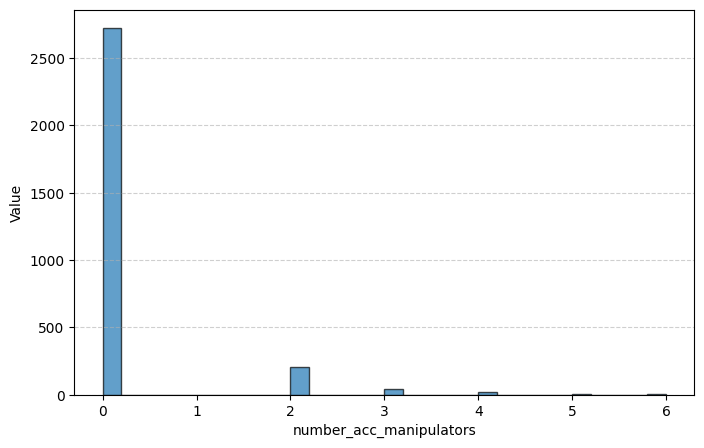

number_acc_manipulators mean: 0.2220
number_acc_manipulators median: 0.0000
number_acc_manipulators max: 6.0000


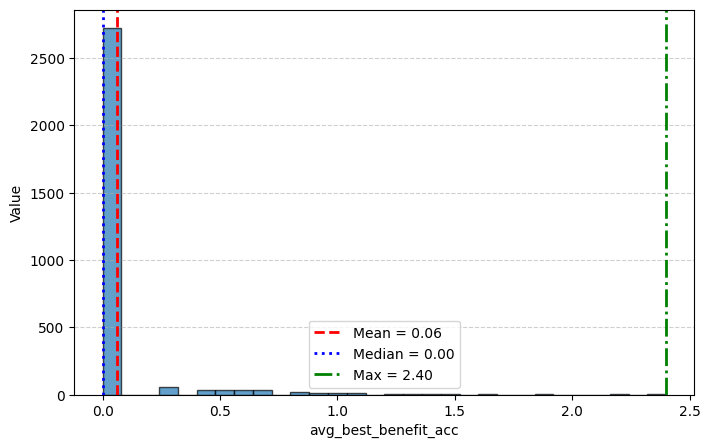

Mean of avg_best_benefit_acc: 0.0622
Median of avg_best_benefit_acc: 0.0000
Max of avg_best_benefit_acc: 2.4000


In [7]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

#df = df[df["number_acc_manipulators"]>0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

#positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = df["avg_best_benefit_acc"].mean()

median_pos = df["avg_best_benefit_acc"].median()

max_pos = df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Mallows MD**

In [43]:
df = pd.read_csv("mallows_MD_gain_test.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_MD_gain_test.csv', index=False)


500it [00:01, 295.28it/s]


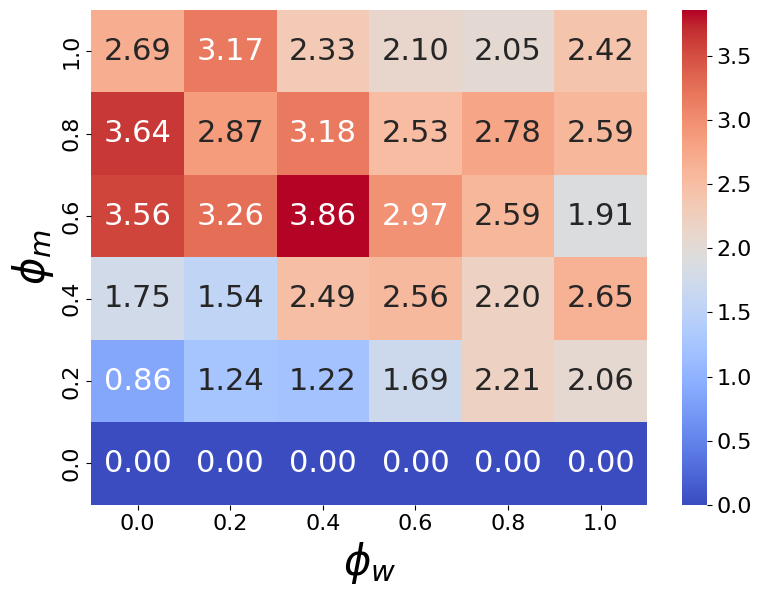

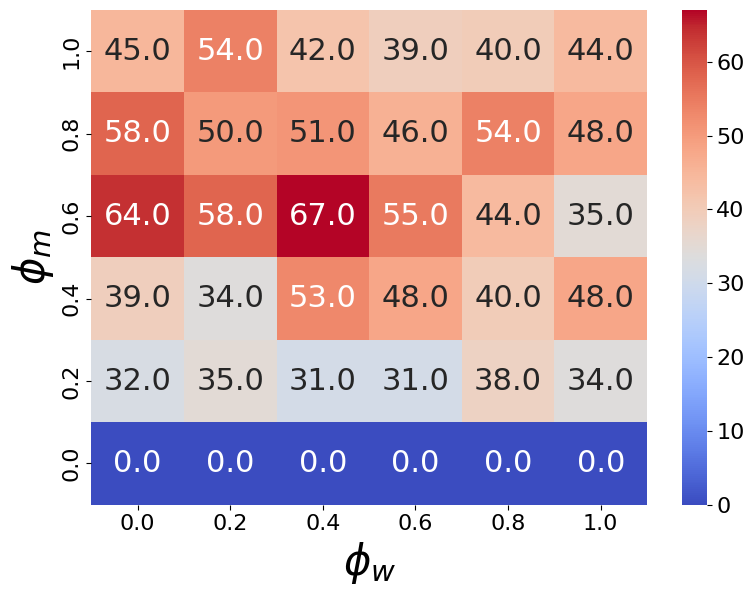

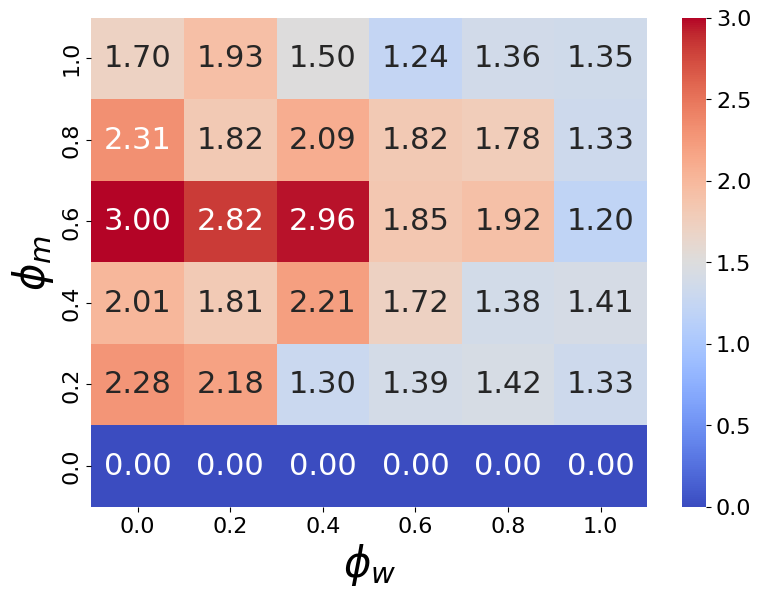

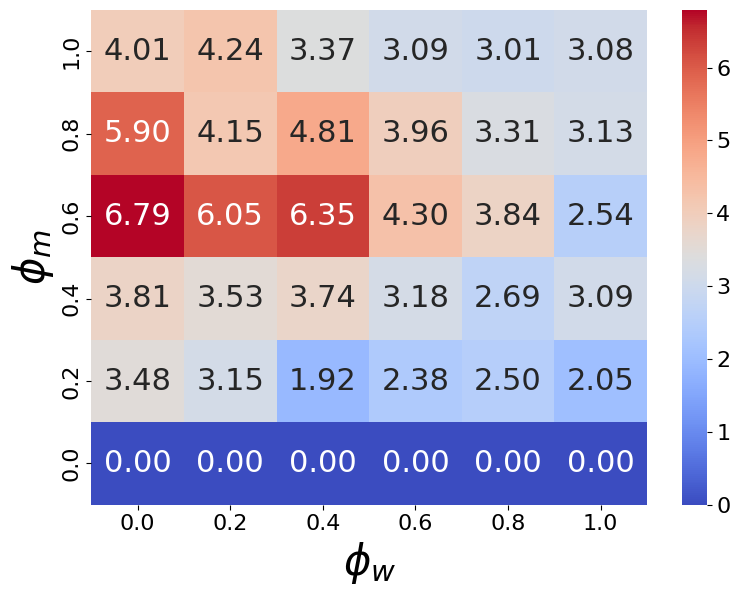

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MD_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MD_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title,filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()

    #heatmap_df = heatmap_df / 100

    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel(r'$\phi_w$', fontsize=30)
    plt.ylabel(r"$\phi_m$", fontsize=30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)
    
    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="coolwarm", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel(r'$\phi_w$', fontsize=30)
    plt.ylabel(r"$\phi_m$", fontsize=30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "mallows_MD_max_best_benefit_acc")
plot_heatmap_sum(df, "acc_freq_instance", "Frequency of Accomplice Manipulation (Instances)", "mallows_MD_acc_freq_instance")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "mallows_MD_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "mallow_MD_number_acc_pairs")



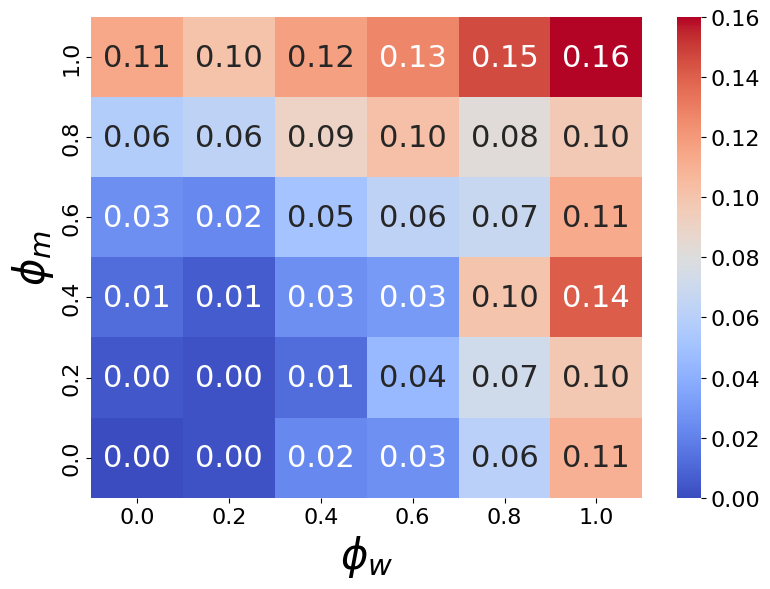

In [48]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_acc_manipulators"].mean().reset_index()

heatmap_data["number_acc_manipulators"] = heatmap_data["number_acc_manipulators"] / 10  # Scale here

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_acc_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_number_acc_manipulators.pdf", format="pdf")
plt.show()


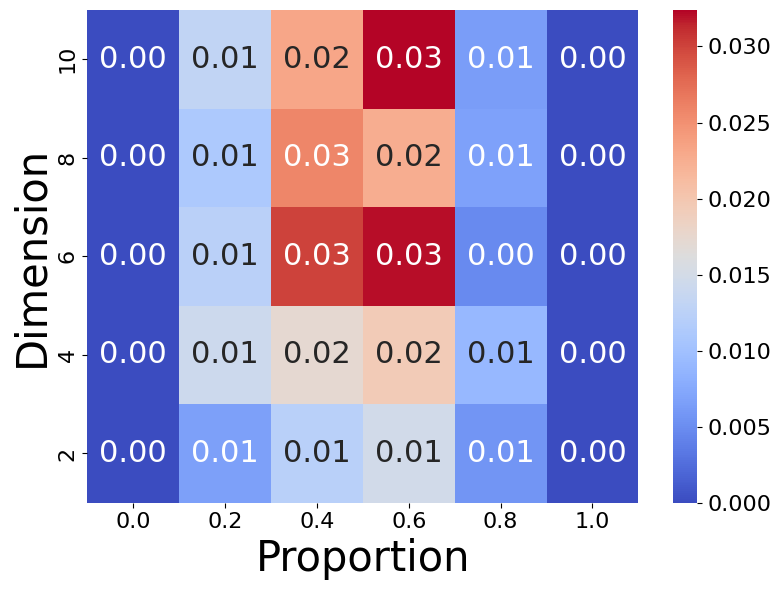

In [41]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["number_acc_pairs"].mean().reset_index()

heatmap_data["number_acc_pairs"] = heatmap_data["number_acc_pairs"] / 100  # Scale here

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="number_acc_pairs")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Proportion", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("reverse_euclidean_gain_number_acc_pairs.pdf", format="pdf")
plt.show()


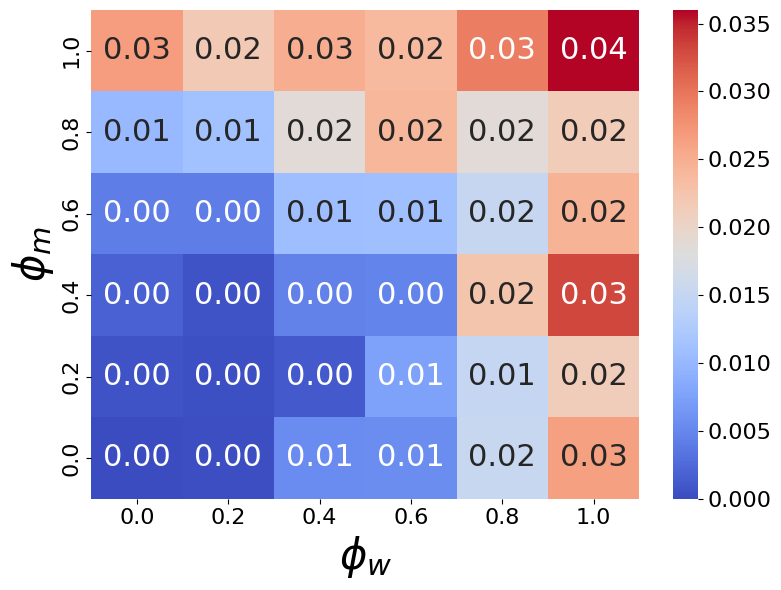

In [49]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_acc_pairs"].mean().reset_index()

heatmap_data["number_acc_pairs"] = heatmap_data["number_acc_pairs"] / 100  # Scale here

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_acc_pairs")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallow_euclidean_number_acc_pairs.pdf", format="pdf")
plt.show()


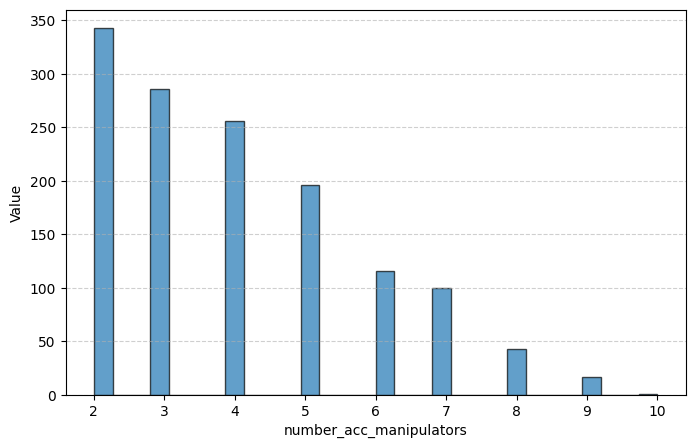

number_acc_manipulators mean: 4.0103
number_acc_manipulators median: 4.0000
number_acc_manipulators max: 10.0000


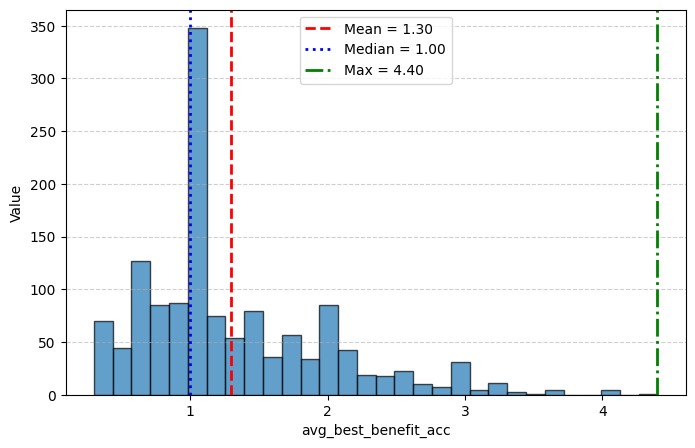

Mean of avg_best_benefit_acc: 1.2993
Median of avg_best_benefit_acc: 1.0000
Max of avg_best_benefit_acc: 4.4000


In [5]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["number_acc_manipulators"]>0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_best_benefit_acc"].mean()

median_pos = positive_df["avg_best_benefit_acc"].median()

max_pos = positive_df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Mallows MA**

In [39]:
df = pd.read_csv("mallows_MA_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_MA_gain.csv', index=False)


3600it [00:08, 417.71it/s]


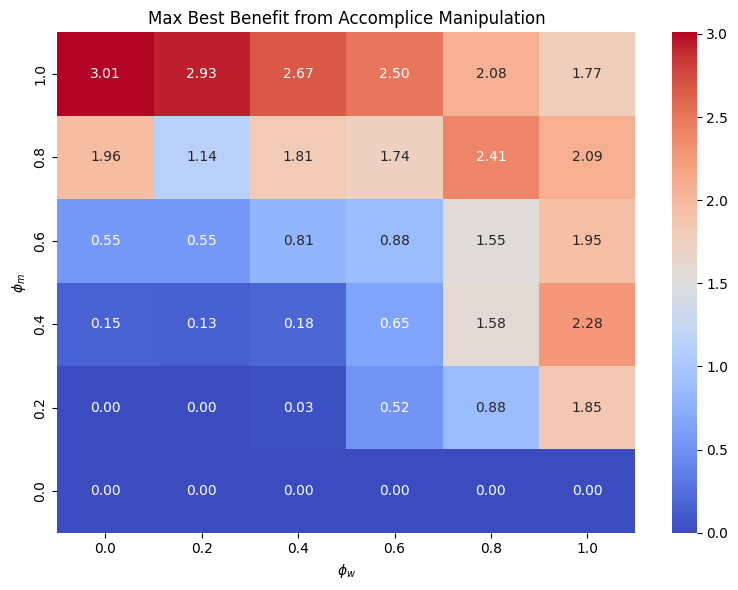

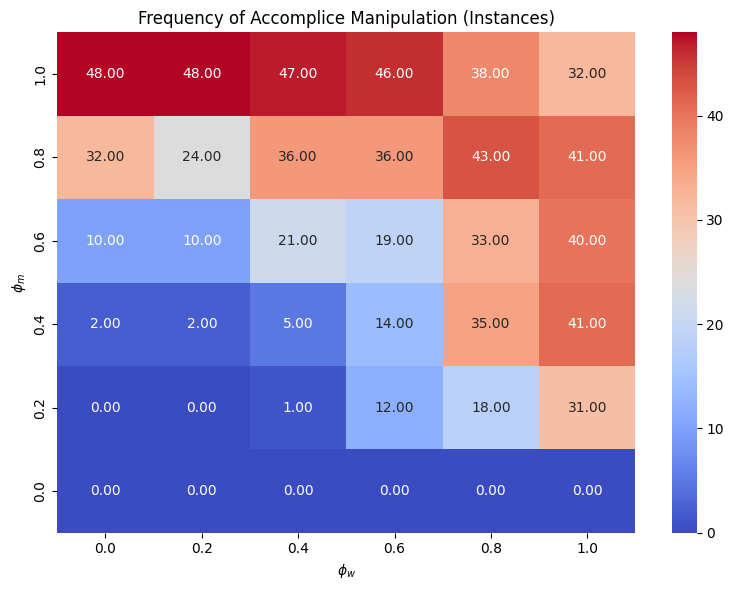

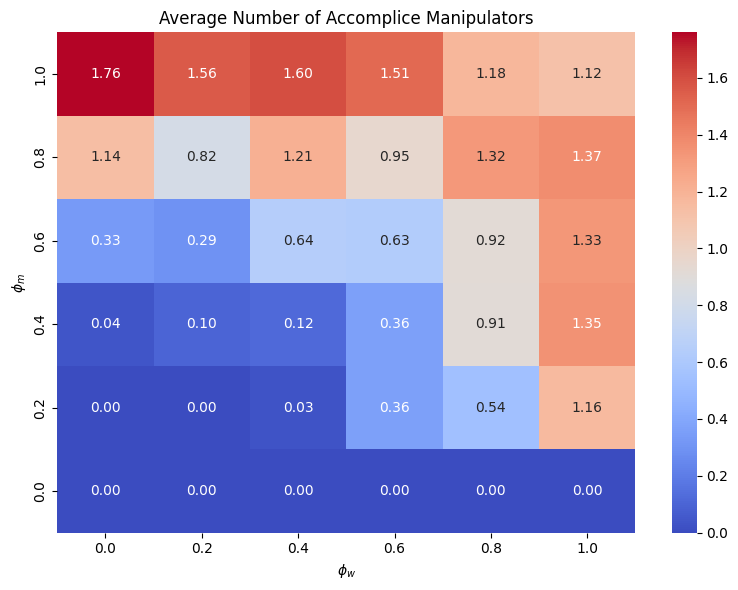

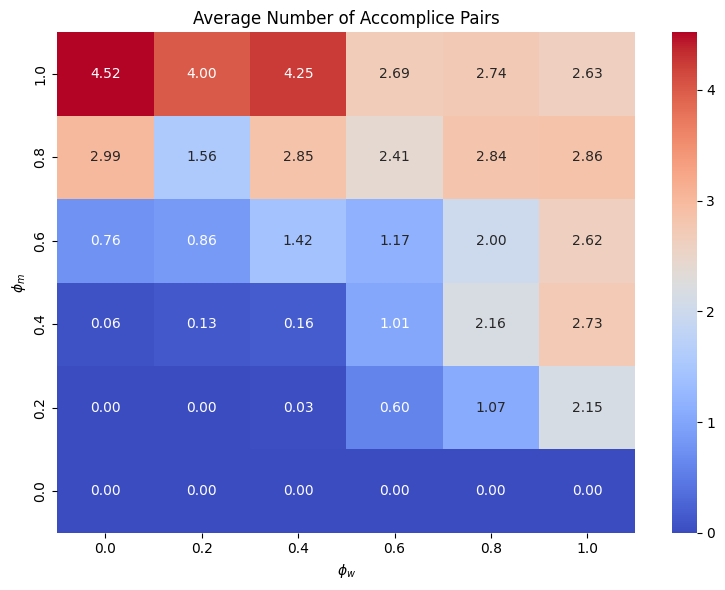

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
best_benefits_list1 = []
max_best_benefit_list = []
avg_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    best_benefits_per_woman = [
    max(result[0] for result in manipulator_results)
    for manipulator_results in accomplice_results
    ]
    best_benefits_list1.append(best_benefits_per_woman)

    # Average across manipulators
    avg_best_benefit_list.append(np.mean(best_benefits_per_woman))

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list
df["avg_best_benefit_acc"] = avg_best_benefit_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title,filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "mallows_MA_max_best_benefit_acc")
plot_heatmap_sum(df, "acc_freq_instance", "Frequency of Accomplice Manipulation (Instances)", "mallows_MA_acc_freq_instance")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "mallows_MA_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "mallow_MA_number_acc_pairs")



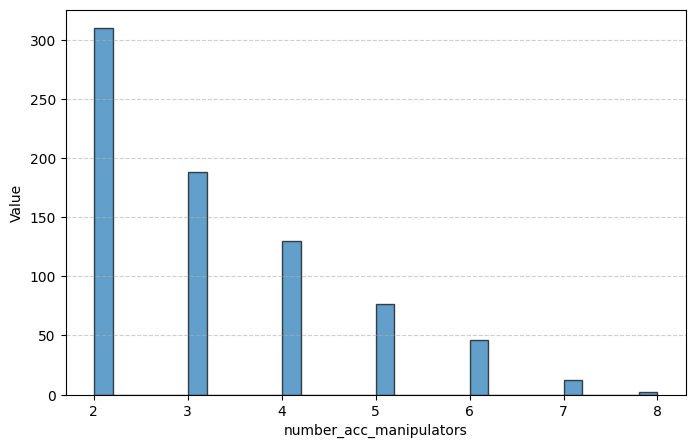

number_acc_manipulators mean: 3.2222
number_acc_manipulators median: 3.0000
number_acc_manipulators max: 8.0000


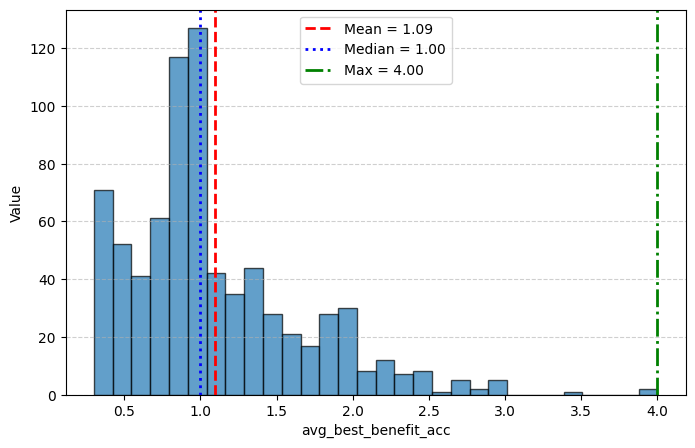

Mean of avg_best_benefit_acc: 1.0928
Median of avg_best_benefit_acc: 1.0000
Max of avg_best_benefit_acc: 4.0000


In [4]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["number_acc_manipulators"] >0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_best_benefit_acc"].mean()

median_pos = positive_df["avg_best_benefit_acc"].median()

max_pos = positive_df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Mallows Euclidean**

In [ ]:
df = pd.read_csv("mallows_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_euclidean_gain_test.csv', index=False)


500it [00:01, 295.22it/s]


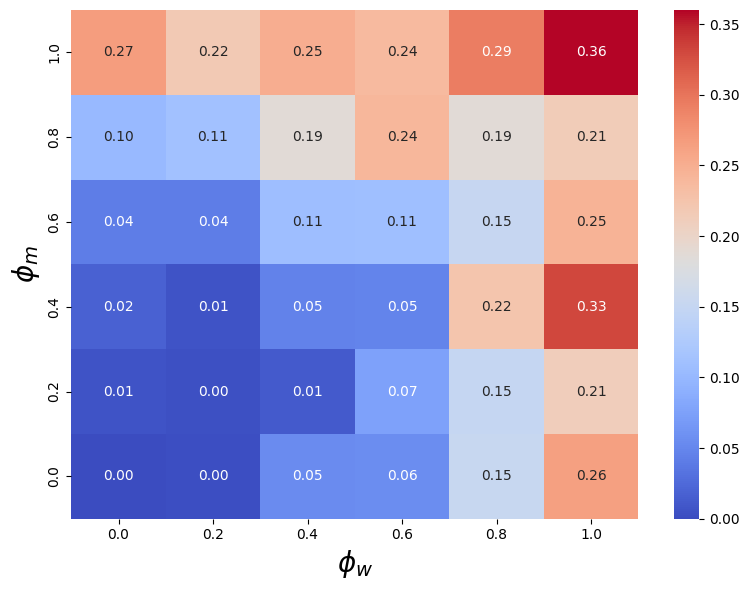

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_euclidean_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_df[value_col] = heatmap_df[value_col] / 10  # Scale here
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    #plt.title(title)
    plt.xlabel(r'$\phi_w$', fontsize = 20)
    plt.ylabel(r"$\phi_m$", fontsize = 20)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
#plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "mallows_euclidean_max_best_benefit_acc")
#plot_heatmap_sum(df, "acc_freq_instance", "Frequency of Accomplice Manipulation (Instances)", "mallows_euclidean_acc_freq_instance")
#plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "mallows_euclidean_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "mallows_euclidean_number_acc_pairs_10")


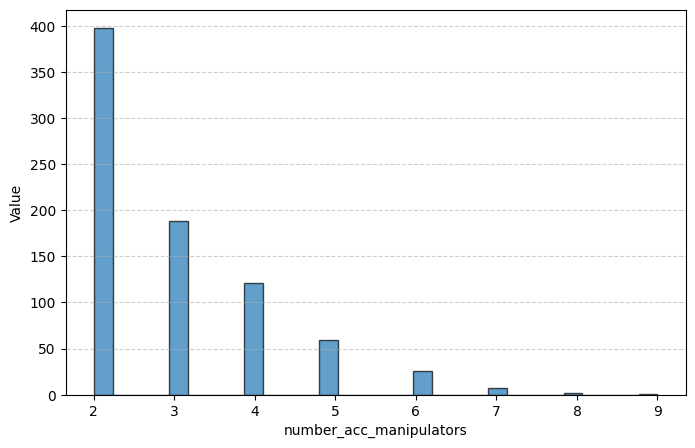

number_acc_manipulators mean: 2.9539
number_acc_manipulators median: 3.0000
number_acc_manipulators max: 9.0000


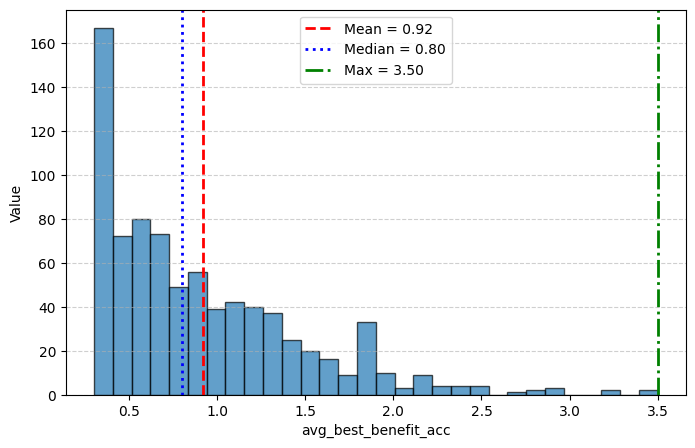

Mean of avg_best_benefit_acc: 0.9187
Median of avg_best_benefit_acc: 0.8000
Max of avg_best_benefit_acc: 3.5000


In [3]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["number_acc_manipulators"] >0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_best_benefit_acc"].mean()

median_pos = positive_df["avg_best_benefit_acc"].median()

max_pos = positive_df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Reverse Euclidean**

In [12]:
df = pd.read_csv("reverse_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('reverse_euclidean_gain.csv', index=False)


3000it [00:08, 344.09it/s]


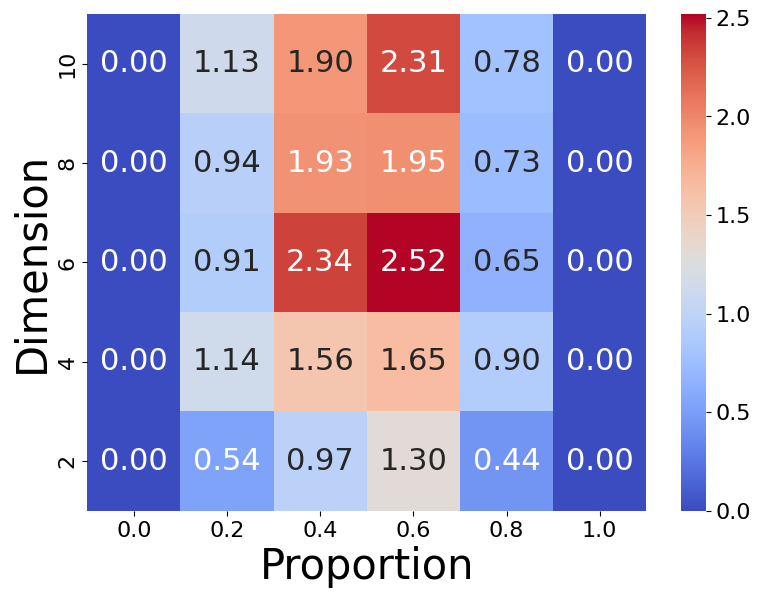

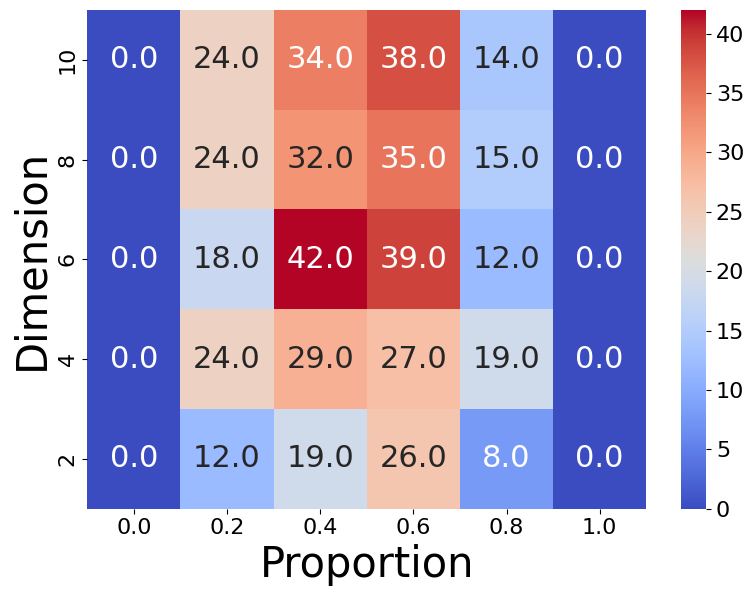

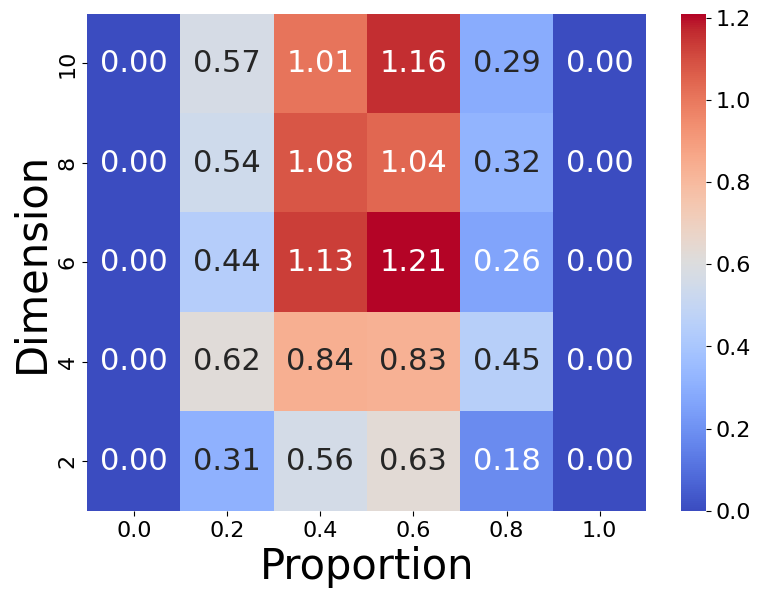

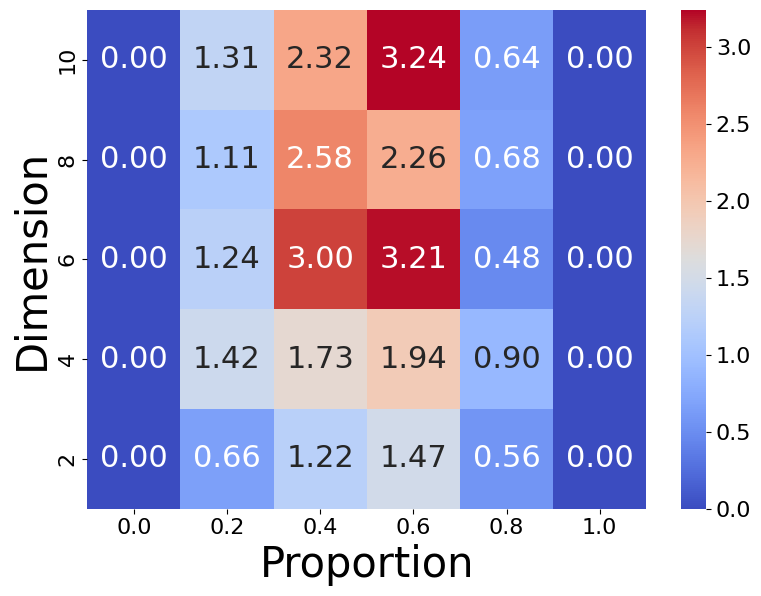

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("reverse_euclidean_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("reverse_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].mean().reset_index()

    #heatmap_df = heatmap_df / 100

    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize = 30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="coolwarm", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize = 30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "reverse_euclidean_gain_max_best_benefit_acc")
plot_heatmap_sum(df, "acc_freq_instance", "Frequency of Accomplice Manipulation (Instances)", "reverse_euclidean_gain_acc_freq_instance")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "reverse_euclidean_gain_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "reverse_euclidean_gain_number_acc_pairs")

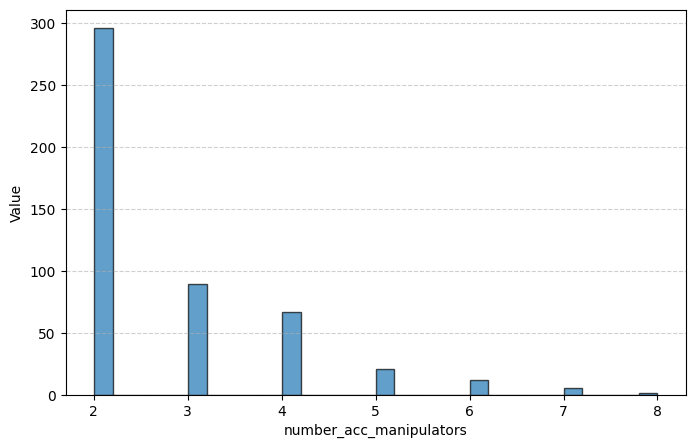

number_acc_manipulators mean: 2.7434
number_acc_manipulators median: 2.0000
number_acc_manipulators max: 8.0000


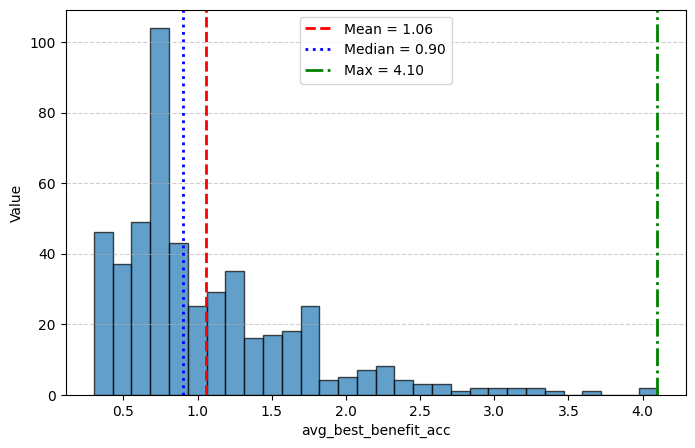

Mean of avg_best_benefit_acc: 1.0595
Median of avg_best_benefit_acc: 0.9000
Max of avg_best_benefit_acc: 4.1000


In [2]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["number_acc_manipulators"] >0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_best_benefit_acc"].mean()

median_pos = positive_df["avg_best_benefit_acc"].median()

max_pos = positive_df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Expectations Euclidean**

In [14]:
df = pd.read_csv("expectations_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('expectations_euclidean_gain.csv', index=False)


3000it [00:14, 201.64it/s]


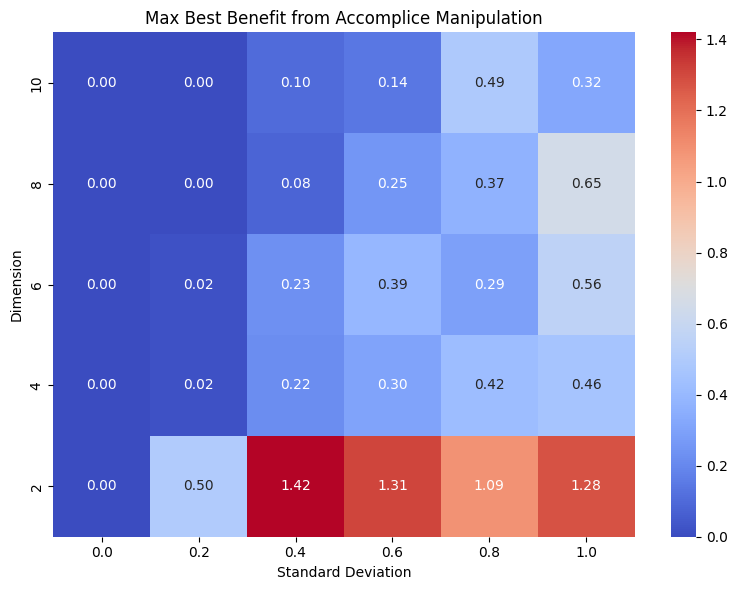

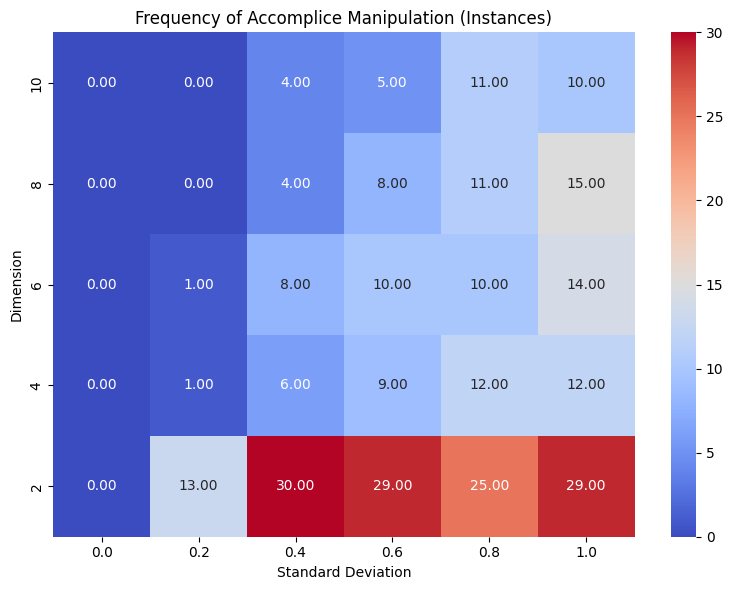

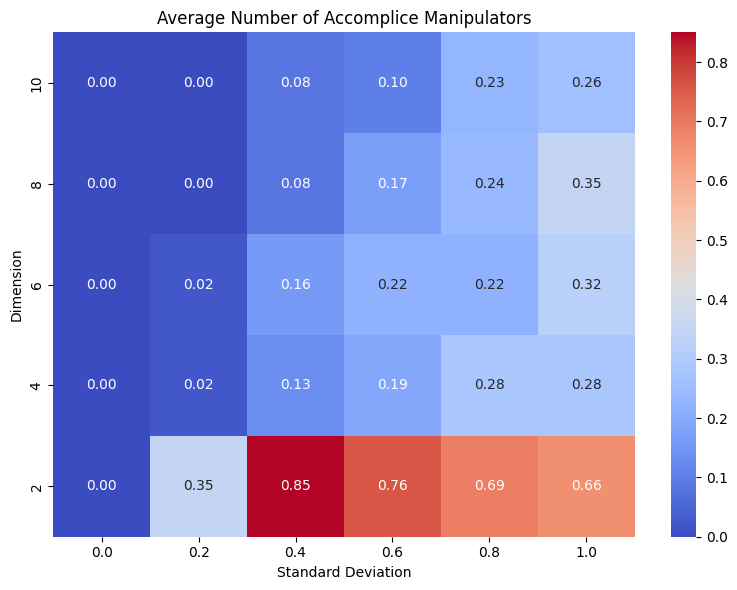

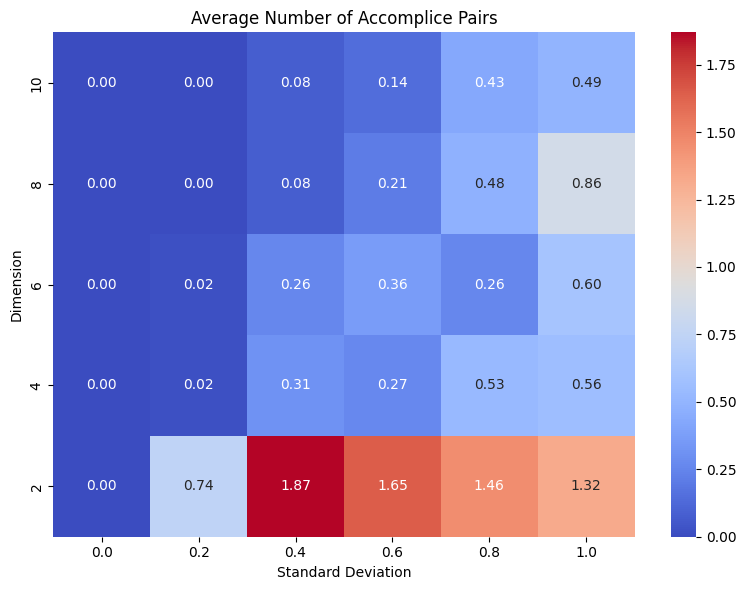

In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("expectations_euclidean_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["max_best_benefit_acc"] = max_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("expectations_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "std"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="std",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Standard Deviation")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "std"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="std",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Standard Deviation")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_acc", "Max Best Benefit from Accomplice Manipulation", "expectations_euclidean_gain_max_best_benefit_acc")
plot_heatmap_sum(df, "acc_freq_instance", "Frequency of Accomplice Manipulation (Instances)", "expectations_euclidean_gain_acc_freq_instance")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators", "expectations_euclidean_gain_number_acc_manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs", "expectations_euclidean_gain_number_acc_pairs")

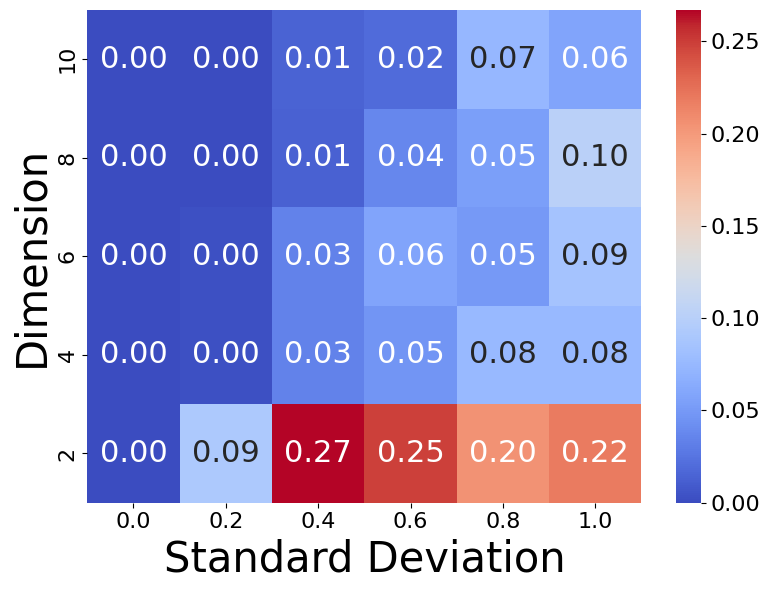

In [14]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["avg_best_benefit_acc"].mean().reset_index()

#heatmap_data["avg_best_benefit_acc"] = heatmap_data["avg_best_benefit_acc"] / 10  # Scale down


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="avg_best_benefit_acc")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_gain_avg_best_benefit_acc.pdf", format="pdf")
plt.show()


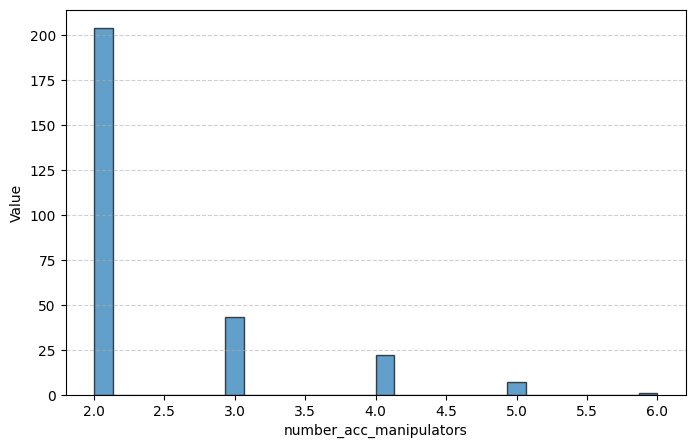

number_acc_manipulators mean: 2.4043
number_acc_manipulators median: 2.0000
number_acc_manipulators max: 6.0000


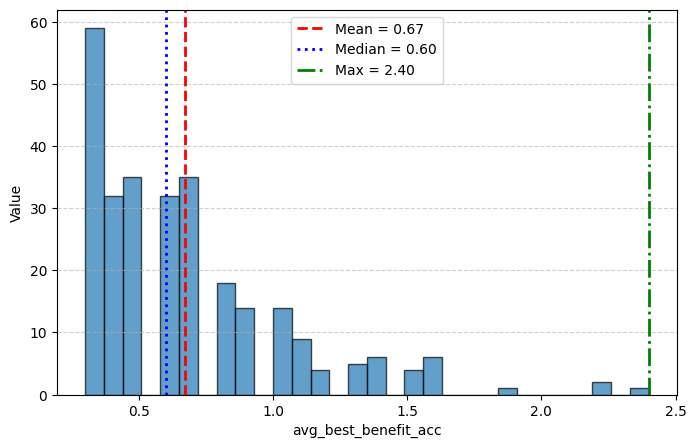

Mean of avg_best_benefit_acc: 0.6736
Median of avg_best_benefit_acc: 0.6000
Max of avg_best_benefit_acc: 2.4000


In [1]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["number_acc_manipulators"] >0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["number_acc_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("number_acc_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["number_acc_manipulators"].mean()

median_val = df["number_acc_manipulators"].median()

max_val = df["number_acc_manipulators"].max()
 
print(f"number_acc_manipulators mean: {mean_val:.4f}")

print(f"number_acc_manipulators median: {median_val:.4f}")

print(f"number_acc_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_best_benefit_acc"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_best_benefit_acc"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_best_benefit_acc")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_best_benefit_acc"].mean()

median_pos = positive_df["avg_best_benefit_acc"].median()

max_pos = positive_df["avg_best_benefit_acc"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_best_benefit_acc: {mean_pos:.4f}")

print(f"Median of avg_best_benefit_acc: {median_pos:.4f}")

print(f"Max of avg_best_benefit_acc: {max_pos:.4f}")

 

**Fame Euclidean**

In [16]:
df = pd.read_csv("fame_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('fame_euclidean_gain.csv', index=False)


2400it [00:07, 307.87it/s]


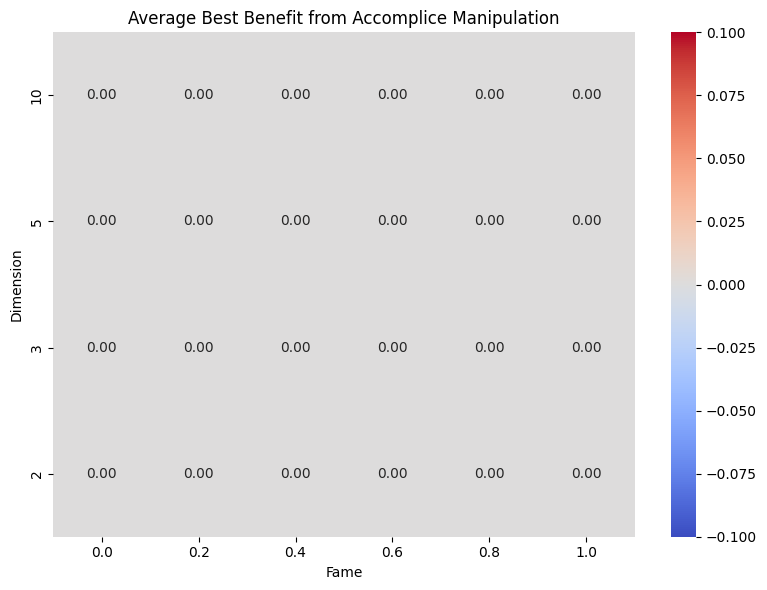

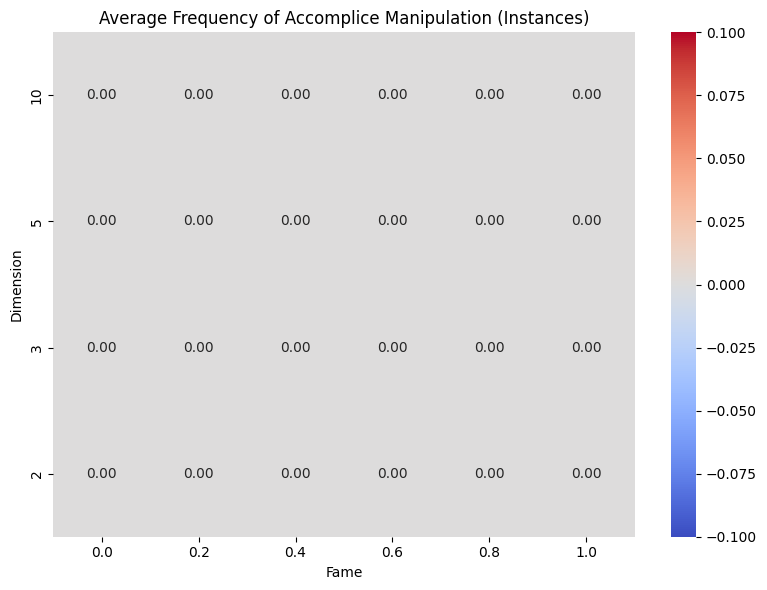

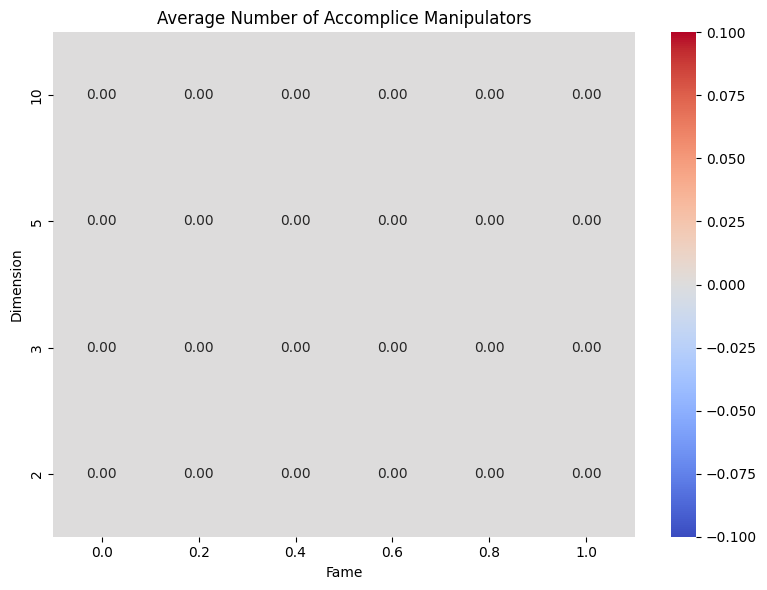

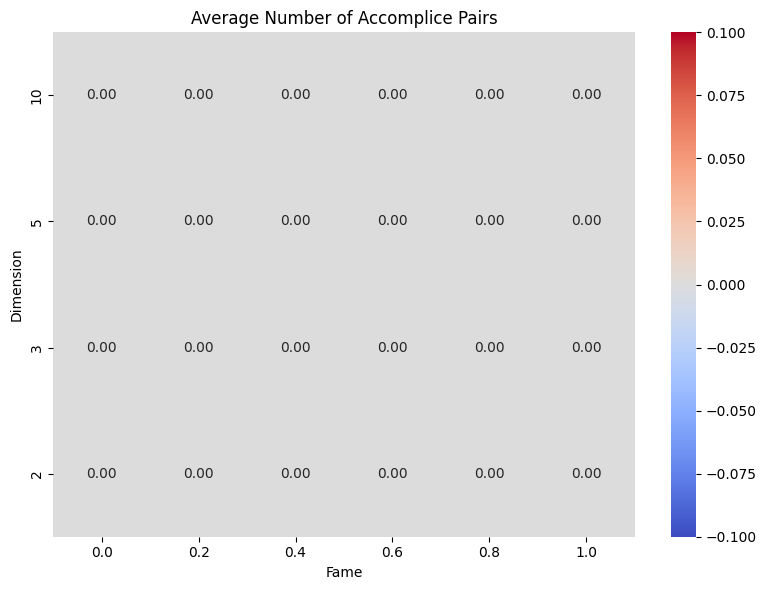

In [24]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("fame_euclidean_gain.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
avg_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_val = np.mean(best_benefits_per_woman)
    avg_best_benefit_list.append(avg_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if avg_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in accomplice_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_acc"] = best_benefits_list
df["avg_best_benefit_acc"] = avg_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("fame_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title):
    heatmap_df = df.groupby(["dimension", "fame"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="fame",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Fame")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "avg_best_benefit_acc", "Average Best Benefit from Accomplice Manipulation")
plot_heatmap(df, "acc_freq_instance", "Average Frequency of Accomplice Manipulation (Instances)")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs")


In [ ]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_two_manipulators"].mean().reset_index()

heatmap_data["number_two_manipulators"] = heatmap_data["number_two_manipulators"] / 10


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_two_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_MD_number_two_manipulators.pdf", format="pdf")
plt.show()
